### 1. Download and Preprocess the IMDB Dataset
We will use the standard IMDB dataset. Let's import the necessary libraries and set up the device (GPU/CPU).

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import re
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Setup GPU configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


#### Download the Dataset
Since we need the IMDB dataset, we can fetch it directly from an online repository or use a public CSV copy for easy loading.

In [2]:
# Load the IMDB dataset directly via pandas
url = 'https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv'
df = pd.read_csv(url)
display(df.head())

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


#### Text Cleaning and Tokenization
We clean the HTML tags, punctuation, and map the tokens to numerical indices.

In [3]:
def clean_text(text):
    text = re.sub(r'<br\s*/?>', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower().strip()
    return text

df['cleaned_review'] = df['review'].apply(clean_text)

# Map labels to integers
df['sentiment'] = df['sentiment'].map({'positive': 1, 'negative': 0})

# Build vocabulary
words = []
for review in df['cleaned_review']:
    words.extend(review.split())

word_counts = Counter(words)
# Keep top 10000 most common words
vocab = {word: i + 2 for i, (word, _) in enumerate(word_counts.most_common(10000))}
vocab['<PAD>'] = 0
vocab['<UNK>'] = 1

def tokenize_and_pad(text, max_len=150):
    tokens = [vocab.get(word, 1) for word in text.split()]
    if len(tokens) < max_len:
        tokens = tokens + [0] * (max_len - len(tokens))
    else:
        tokens = tokens[:max_len]
    return tokens

df['tokenized'] = df['cleaned_review'].apply(lambda x: tokenize_and_pad(x))

# Split Dataset
X = np.array(df['tokenized'].tolist())
y = df['sentiment'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#### PyTorch Dataset and DataLoader Setup

In [4]:
class IMDBDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = IMDBDataset(X_train, y_train)
test_dataset = IMDBDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

### 2. Implement LSTM and Bi-LSTM Architectures in PyTorch

In [5]:
class SentimentClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, num_layers, bidirectional=False):
        super(SentimentClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            bidirectional=bidirectional,
            batch_first=True,
            dropout=0.5 if num_layers > 1 else 0.0
        )
        multiplier = 2 if bidirectional else 1
        self.fc = nn.Linear(hidden_dim * multiplier, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, text):
        embedded = self.embedding(text)
        lstm_out, (hidden, cell) = self.lstm(embedded)
        # Use the last hidden state representing the output sequence
        if self.lstm.bidirectional:
            # Concatenate the final forward and backward hidden states
            hidden_concat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
            out = self.fc(hidden_concat)
        else:
            out = self.fc(hidden[-1,:,:])
        return self.sigmoid(out).squeeze()

### 3 & 4. Train and Evaluate Function Helpers

In [6]:
def train_model(model, train_loader, criterion, optimizer, epochs=5):
    model.train()
    epoch_losses = []
    for epoch in range(epochs):
        total_loss = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            predictions = model(inputs)
            loss = criterion(predictions, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(train_loader)
        epoch_losses.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")
    return epoch_losses

def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            predictions = model(inputs)
            rounded_preds = torch.round(predictions)
            correct += (rounded_preds == labels).sum().item()
            total += labels.size(0)
    return correct / total

### 5 & 6. Training, Evaluation, and Comparison

In [7]:
vocab_size = len(vocab)
embedding_dim = 100
hidden_dim = 128
output_dim = 1
num_layers = 1

# 1. Train Standard LSTM
print("--- Training Standard LSTM ---")
lstm_model = SentimentClassifier(vocab_size, embedding_dim, hidden_dim, output_dim, num_layers, bidirectional=False).to(device)
optimizer_lstm = optim.Adam(lstm_model.parameters(), lr=0.001)
criterion = nn.BCELoss()
lstm_losses = train_model(lstm_model, train_loader, criterion, optimizer_lstm, epochs=5)
lstm_acc = evaluate_model(lstm_model, test_loader)
print(f"Standard LSTM Accuracy: {lstm_acc * 100:.2f}%")

# 2. Train Bidirectional LSTM
print("\n--- Training Bidirectional LSTM ---")
bilstm_model = SentimentClassifier(vocab_size, embedding_dim, hidden_dim, output_dim, num_layers, bidirectional=True).to(device)
optimizer_bilstm = optim.Adam(bilstm_model.parameters(), lr=0.001)
bilstm_losses = train_model(bilstm_model, train_loader, criterion, optimizer_bilstm, epochs=5)
bilstm_acc = evaluate_model(bilstm_model, test_loader)
print(f"Bi-LSTM Accuracy: {bilstm_acc * 100:.2f}%")

--- Training Standard LSTM ---
Epoch 1/5 | Loss: 0.6907
Epoch 2/5 | Loss: 0.6569
Epoch 3/5 | Loss: 0.6644
Epoch 4/5 | Loss: 0.5531
Epoch 5/5 | Loss: 0.3607
Standard LSTM Accuracy: 84.48%

--- Training Bidirectional LSTM ---
Epoch 1/5 | Loss: 0.6659
Epoch 2/5 | Loss: 0.5034
Epoch 3/5 | Loss: 0.3533
Epoch 4/5 | Loss: 0.2796
Epoch 5/5 | Loss: 0.2284
Bi-LSTM Accuracy: 86.20%


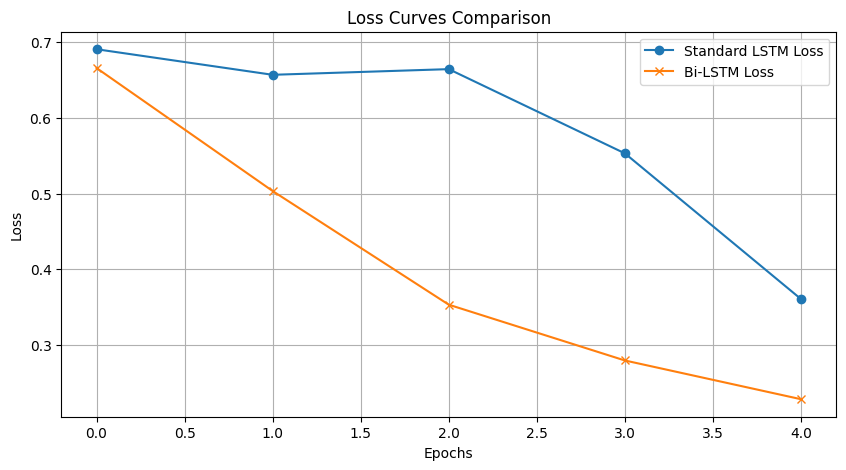

In [8]:
# Visualize Loss Curves
plt.figure(figsize=(10, 5))
plt.plot(lstm_losses, label='Standard LSTM Loss', marker='o')
plt.plot(bilstm_losses, label='Bi-LSTM Loss', marker='x')
plt.title('Loss Curves Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()